#  Smart Mock Interview Assistant EDA

This notebook explores the processed `questions_cleaned.json` file for the Smart Mock Interview Assistant project.

The aim is to check whether the processed question bank is clean and balanced.

## EDA Goals

- Check the dataset structure and basic record counts.
- Review missing values and blank fields.
- Analyse the distribution of domains and difficulty levels.
- Check domain and difficulty balance together.
- Analyse question and reference-answer text lengths.
- Detect duplicate or repeated records.
- Identify text-quality issues such as encoding artefacts and unusual whitespace.
- Produce practical recommendations for improving the question bank before modelling.

In [1]:
from pathlib import Path
import json
import re

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_rows", 100)

In [3]:
def find_project_root(start: Path) -> Path:
    """Find the project root by locating the cleaned dataset."""
    for path in [start, *start.parents]:
        if (path / "data" / "processed" / "questions_cleaned.json").exists():
            return path
    raise FileNotFoundError("Could not find data/processed/questions_cleaned from this notebook location.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "questions_cleaned.json"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "eda" / "questions_eda_outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT, DATA_PATH, FIGURES_DIR

## 1. Load Dataset

In [4]:
with DATA_PATH.open("r", encoding="utf-8") as file:
    records = json.load(file)

df = pd.DataFrame(records)
df.head()

,id,domain,difficulty,question,reference_answer
0,1,DATA_ANALYSIS,Easy,What is R2? What are some other metrics that could be better than R2 and why?,goodness of fit measure. variance explained by the regression / total variance. the more predictors you add the higher R^2 becomes. henc...
1,2,DATA_ANALYSIS,Medium,What is the curse of dimensionality?,"High dimensionality makes clustering hard, because having lots of dimensions means that everything is ""far away"" from each other.\nFor e..."
2,3,DATA_ANALYSIS,Easy,Is more data always better?,"- Statistically,\nIt depends on the quality of your data, for example, if your data is biased, just getting more data won’t help.\nIt de..."
3,4,DATA_ANALYSIS,Easy,What are advantages of plotting your data before per- forming analysis?,Data sets have errors. You won't find them all but you might find some. That 212 year old man. That 9 foot tall woman.\nVariables can h...
4,5,DATA_ANALYSIS,Medium,How can you make sure that you don’t analyze something that ends up meaningless?,"Proper exploratory data analysis.\nIn every data analysis task, there's the exploratory phase where you're just graphing things, testing..."


In [5]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.dtypes.rename("dtype").to_frame())
display(df.describe(include="all"))

Rows: 468
Columns: 5


,dtype
id,int64
domain,object
difficulty,object
question,object
reference_answer,object


,id,domain,difficulty,question,reference_answer
count,468.000000,468,468,468,468
unique,NaN,7,4,468,467
top,NaN,ML,Medium,Implement a generator function in Python.,SVM algorithms have basically advantages in terms of complexity. First I would like to clear that both Logistic regression as well as SV...
freq,NaN,206,202,1,2
mean,247.461538,NaN,NaN,NaN,NaN
std,163.515948,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN
25%,119.750000,NaN,NaN,NaN,NaN
50%,236.500000,NaN,NaN,NaN,NaN
75%,353.250000,NaN,NaN,NaN,NaN


## 2. Schema and ID Checks

In [6]:
expected_columns = ["id", "domain", "difficulty", "question", "reference_answer"]

schema_check = pd.DataFrame({
    "expected_column": expected_columns,
    "present": [column in df.columns for column in expected_columns],
})

extra_columns = sorted(set(df.columns) - set(expected_columns))

display(schema_check)
print("Extra columns:", extra_columns if extra_columns else "None")

,expected_column,present
0,id,True
1,domain,True
2,difficulty,True
3,question,True
4,reference_answer,True


Extra columns: None


In [7]:
# Convert IDs to numeric before sequence checks so the integer or string IDs are handled safely.
id_numeric = pd.to_numeric(df["id"], errors="coerce")
non_numeric_ids = df[id_numeric.isna()]["id"].tolist()

id_summary = {
    "unique_raw_ids": df["id"].nunique(),
    "unique_numeric_ids": id_numeric.nunique(),
    "duplicate_raw_id_rows": int(df["id"].duplicated().sum()),
    "duplicate_numeric_id_rows": int(id_numeric.duplicated().sum()),
    "non_numeric_id_rows": int(id_numeric.isna().sum()),
    "min_id": int(id_numeric.min()) if id_numeric.notna().any() else None,
    "max_id": int(id_numeric.max()) if id_numeric.notna().any() else None,
    "row_count": len(df),
}

if id_numeric.notna().any():
    expected_ids = set(range(int(id_numeric.min()), int(id_numeric.max()) + 1))
    actual_ids = set(id_numeric.dropna().astype(int))
    missing_ids = sorted(expected_ids - actual_ids)
else:
    missing_ids = []

display(pd.Series(id_summary, name="value").to_frame())
print("Missing IDs in sequence:", missing_ids if missing_ids else "None")
print("Non-numeric IDs:", non_numeric_ids if non_numeric_ids else "None")

,value
unique_raw_ids,468
unique_numeric_ids,468
duplicate_raw_id_rows,0
duplicate_numeric_id_rows,0
non_numeric_id_rows,0
min_id,1
max_id,885
row_count,468


Missing IDs in sequence: [70, 86, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 506, 507, 508, 509, 510, 512, 513, 514, 515, 516, 517, 518, 519, 520, 521, 522, 523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538, 539, 540, 541, 542, 543, 544, 545, 546, 547, 548, 549, 550, 551, 552, 553, 554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565, 566, 567, 568, 569, 570, 571, 572, 573, 574, 575, 576, 577, 578, 579, 580, 581, 582, 585, 588, 589, 590, 591, 592, 594, 595, 596, 597, 598, 599, 600, 601, 602, 603, 604, 605, 606, 607, 608, 609, 610, 611, 612, 613, 614, 615, 616, 617, 618, 619, 620, 621, 622, 623, 624, 625, 626, 627, 628, 629, 630, 631, 632, 633, 634, 635, 636, 637, 638, 639, 640, 641, 642, 643, 644, 645, 646, 647, 648, 649, 6

## 3. Missing and Blank Value Analysis

This section checks both true missing values and blank strings. Blank strings matter here because `difficulty` may be present but empty.

In [8]:
text_columns = ["domain", "difficulty", "question", "reference_answer"]

blank_counts = df[text_columns].apply(lambda col: col.astype(str).str.strip().eq("").sum())
missing_counts = df.isna().sum()

quality_counts = pd.DataFrame({
    "missing_values": missing_counts,
    "blank_strings": blank_counts.reindex(df.columns, fill_value=0),
})

quality_counts["total_missing_or_blank"] = quality_counts["missing_values"] + quality_counts["blank_strings"]
display(quality_counts)

,missing_values,blank_strings,total_missing_or_blank
id,0,0,0
domain,0,0,0
difficulty,0,1,1
question,0,0,0
reference_answer,0,0,0


In [9]:
blank_difficulty_rows = df[df["difficulty"].astype(str).str.strip().eq("")]
blank_difficulty_rows

,id,domain,difficulty,question,reference_answer
325,328,ML,,Explain the phrase Curse of Dimensionality.,The Curse of Dimensionality refers to the situation when your data has too many features.


## 4. Domain Distribution

In [10]:
domain_counts = (
    df["domain"]
    .fillna("Missing")
    .replace("", "Blank")
    .value_counts()
    .rename_axis("domain")
    .reset_index(name="count")
)
domain_counts["percentage"] = (domain_counts["count"] / len(df) * 100).round(2)
domain_counts

,domain,count,percentage
0,ML,206,44.02
1,DL,108,23.08
2,NLP,37,7.91
3,PREDICTIVE_MODELLING,34,7.26
4,SQL,30,6.41
5,Python,28,5.98
6,DATA_ANALYSIS,25,5.34


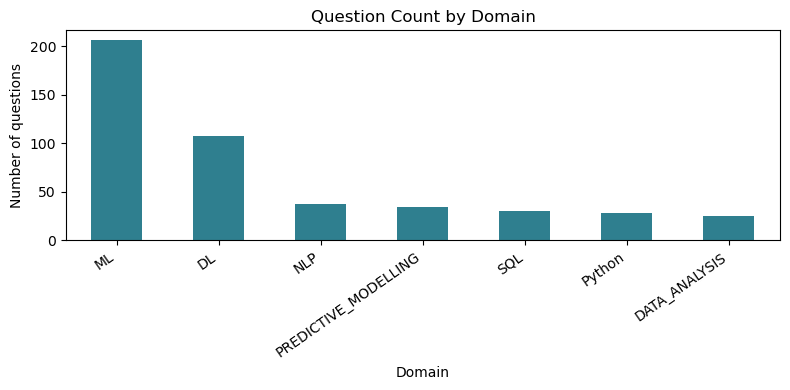

In [11]:
ax = domain_counts.plot.bar(x="domain", y="count", legend=False, figsize=(8, 4), color="#2f7f8f")
ax.set_title("Question Count by Domain")
ax.set_xlabel("Domain")
ax.set_ylabel("Number of questions")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "domain_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Difficulty Distribution

In [12]:
difficulty_clean = df["difficulty"].fillna("Missing").astype(str).str.strip().replace("", "Blank")

difficulty_counts = (
    difficulty_clean
    .value_counts()
    .rename_axis("difficulty")
    .reset_index(name="count")
)
difficulty_counts["percentage"] = (difficulty_counts["count"] / len(df) * 100).round(2)
difficulty_counts

,difficulty,count,percentage
0,Medium,202,43.16
1,Easy,156,33.33
2,Hard,109,23.29
3,Blank,1,0.21


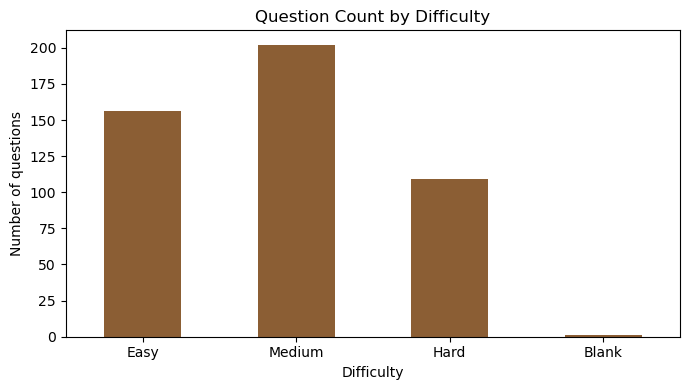

In [13]:
order = [level for level in ["Easy", "Medium", "Hard", "Blank", "Missing"] if level in difficulty_counts["difficulty"].tolist()]
plot_data = difficulty_counts.set_index("difficulty").loc[order].reset_index()
ax = plot_data.plot.bar(x="difficulty", y="count", legend=False, figsize=(7, 4), color="#8b5e34")
ax.set_title("Question Count by Difficulty")
ax.set_xlabel("Difficulty")
ax.set_ylabel("Number of questions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "difficulty_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Domain vs Difficulty

This is useful for deciding whether the app can fairly generate interviews by topic and difficulty.

In [14]:
df_analysis = df.copy()
df_analysis["difficulty_clean"] = difficulty_clean

domain_difficulty = pd.crosstab(df_analysis["domain"], df_analysis["difficulty_clean"])

preferred_order = [level for level in ["Easy", "Medium", "Hard", "Blank", "Missing"] if level in domain_difficulty.columns]
domain_difficulty = domain_difficulty[preferred_order]
domain_difficulty

difficulty_clean,Easy,Medium,Hard,Blank
domain,,,,
DATA_ANALYSIS,4,12,9,0
DL,54,40,14,0
ML,47,107,51,1
NLP,24,8,5,0
PREDICTIVE_MODELLING,7,15,12,0
Python,10,10,8,0
SQL,10,10,10,0


In [15]:
domain_difficulty_pct = domain_difficulty.div(domain_difficulty.sum(axis=1), axis=0).mul(100).round(2)
domain_difficulty_pct

difficulty_clean,Easy,Medium,Hard,Blank
domain,,,,
DATA_ANALYSIS,16.00,48.00,36.00,0.00
DL,50.00,37.04,12.96,0.00
ML,22.82,51.94,24.76,0.49
NLP,64.86,21.62,13.51,0.00
PREDICTIVE_MODELLING,20.59,44.12,35.29,0.00
Python,35.71,35.71,28.57,0.00
SQL,33.33,33.33,33.33,0.00


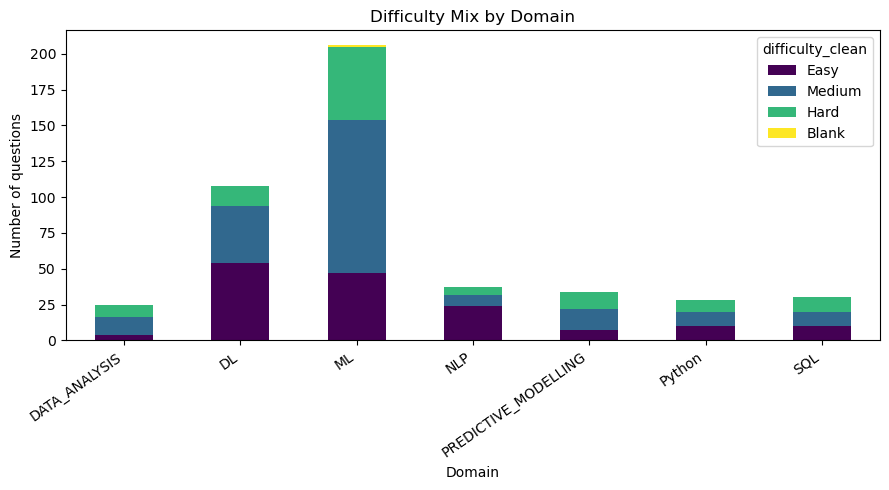

In [16]:
ax = domain_difficulty.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="viridis")
ax.set_title("Difficulty Mix by Domain")
ax.set_xlabel("Domain")
ax.set_ylabel("Number of questions")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "domain_difficulty_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Text Length Analysis

In [17]:
def word_count(value):
    if pd.isna(value):
        return 0
    return len(re.findall(r"\b\w+\b", str(value)))


df_analysis["question_char_len"] = df_analysis["question"].fillna("").astype(str).str.len()
df_analysis["answer_char_len"] = df_analysis["reference_answer"].fillna("").astype(str).str.len()
df_analysis["question_word_count"] = df_analysis["question"].apply(word_count)
df_analysis["answer_word_count"] = df_analysis["reference_answer"].apply(word_count)

length_summary = df_analysis[[
    "question_char_len",
    "question_word_count",
    "answer_char_len",
    "answer_word_count",
]].describe().round(2)

length_summary

,question_char_len,question_word_count,answer_char_len,answer_word_count
count,468.00,468.00,468.00,468.00
mean,57.03,9.75,298.97,48.19
std,39.60,6.92,225.92,37.62
min,12.00,2.00,5.00,1.00
25%,30.00,5.00,129.00,19.00
50%,47.00,8.00,243.00,39.00
75%,68.00,12.00,405.75,66.25
max,305.00,51.00,1757.00,282.00


In [18]:
short_answers = df_analysis.sort_values("answer_word_count").head(15)[[
    "id", "domain", "difficulty", "question", "reference_answer", "answer_word_count"
]]

long_answers = df_analysis.sort_values("answer_word_count", ascending=False).head(10)[[
    "id", "domain", "difficulty", "question", "reference_answer", "answer_word_count"
]]

display(short_answers)
display(long_answers)

,id,domain,difficulty,question,reference_answer,answer_word_count
9,10,DATA_ANALYSIS,Easy,Let’s say you’re given an unfeasible amount of predictors in a predictive modeling task. What are some ways to make the prediction more ...,- PCA,1
418,421,SQL,Easy,What is a NULL value?,Represents missing or unknown information.,5
428,431,SQL,Medium,What is a self join?,A table joined with itself.,5
427,430,SQL,Medium,Explain ACID properties.,"Atomicity, Consistency, Isolation and Durability.",5
437,440,SQL,Hard,What is sharding?,Distributing data across multiple servers.,5
431,434,SQL,Hard,Difference between ROW_NUMBER and RANK?,ROW_NUMBER is unique; RANK allows ties.,6
420,423,SQL,Medium,What is a subquery?,A query nested inside another query.,6
434,437,SQL,Hard,What is a clustered index?,Determines physical storage order of rows.,6
432,435,SQL,Hard,What is query optimization?,Improving execution efficiency of SQL queries.,6
435,438,SQL,Hard,What is a non-clustered index?,Stores pointers to actual table rows.,6


,id,domain,difficulty,question,reference_answer,answer_word_count
65,66,DL,Easy,What are the issues faced while training in Recurrent Networks?,"Recurrent Neural Network uses backpropagation algorithm for training, but it is applied on every timestamp. It is usually known as Back-...",282
63,64,DL,Medium,What do you understand by a convolutional neural network?,"A convolutional neural network, often called CNN, is a feedforward neural network. It uses convolution in at least one of its layers. Th...",197
13,14,DATA_ANALYSIS,Hard,"What is the main idea behind ensemble learning? If I had many different models that predicted the same response variable, what might I w...",The assumption is that a group of weak learners can be combined to form a strong learner.\nHence the combined model is expected to perfo...,194
120,123,DL,Medium,Suppose you have a NN with 3 layers and ReLU activations. What will happen if we initialize all the weights with the same value? what if...,"Solution: If we initialize all the weights to be the same we would not be able to break the symmetry; i.e, all gradients will be updated...",191
118,121,DL,Medium,What are some advantages in using a CNN (convolutional neural network) rather than a DNN (dense neural network) in an image classificati...,"Solution: while both models can capture the relationship between close pixels, CNNs have the following properties: It is translation inv...",190
150,153,ML,Medium,What is Confusion Metrics,"Confusion Matrix is an NxN matrix where N is the no. of classes, that summarizes how successful a classification model's predictions are...",187
250,253,ML,Medium,How would you evaluate a logistic regression model?,"Model Evaluation is a very important part in any analysis to answer the following questions, How well does the model fit the data?, Whic...",185
85,88,DL,Medium,How can hyperparameters be trained in neural networks?,Hyperparameters can be trained using four components as shown below: Batch size: This is used to denote the size of the input chunk. Bat...,149
351,354,NLP,Easy,What is Latent Semantic Indexing (LSI)?,Latent semantic indexing is a mathematical technique used to improve the accuracy of the information retrieval process. The design of LS...,147
26,27,DL,Easy,"What are the main differences between AI, Machine Learning, and Deep Learning?",AI stands for Artificial Intelligence. It is a technique which enables machines to mimic human behavior. Machine Learning is a subset of...,143


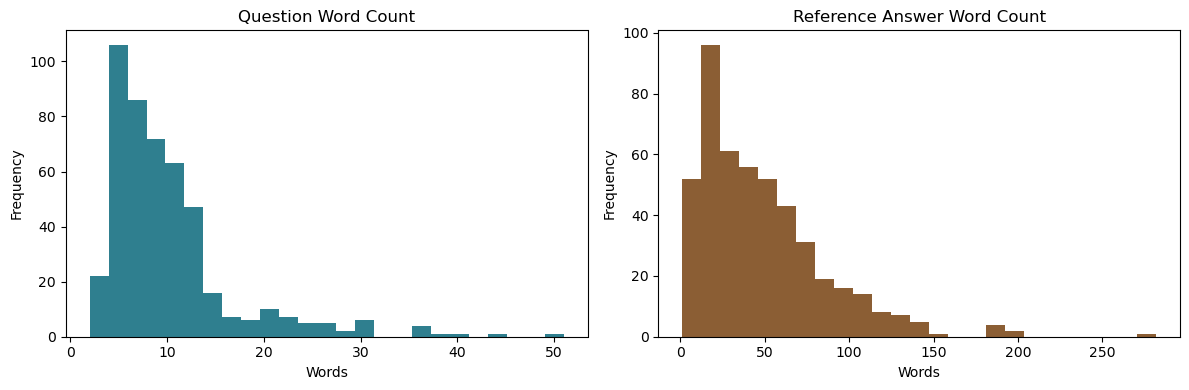

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_analysis["question_word_count"].plot.hist(bins=25, ax=axes[0], color="#2f7f8f")
axes[0].set_title("Question Word Count")
axes[0].set_xlabel("Words")
df_analysis["answer_word_count"].plot.hist(bins=25, ax=axes[1], color="#8b5e34")
axes[1].set_title("Reference Answer Word Count")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "text_length_histograms.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Duplicate Detection

In [20]:
def normalise_text(value):
    if pd.isna(value):
        return ""
    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^a-z0-9 ]", "", value)
    return value


df_analysis["question_normalised"] = df_analysis["question"].apply(normalise_text)
df_analysis["answer_normalised"] = df_analysis["reference_answer"].apply(normalise_text)

duplicate_summary = pd.Series({
    "exact_duplicate_questions": int(df_analysis["question"].duplicated().sum()),
    "normalised_duplicate_questions": int(df_analysis["question_normalised"].duplicated().sum()),
    "exact_duplicate_answers": int(df_analysis["reference_answer"].duplicated().sum()),
    "normalised_duplicate_answers": int(df_analysis["answer_normalised"].duplicated().sum()),
})

duplicate_summary.to_frame("count")

,count
exact_duplicate_questions,0
normalised_duplicate_questions,3
exact_duplicate_answers,1
normalised_duplicate_answers,1


In [21]:
duplicate_questions = df_analysis[df_analysis["question_normalised"].duplicated(keep=False)].sort_values("question_normalised")
duplicate_questions[["id", "domain", "difficulty", "question", "reference_answer"]].head(30)

,id,domain,difficulty,question,reference_answer
354,357,NLP,Easy,Explain Dependency Parsing in NLP.,"Dependency parsing helps assign a syntactic structure to a sentence. Therefore, it is also called syntactic parsing. Dependency parsing ..."
365,368,NLP,Easy,Explain Dependency Parsing in NLP?,"Dependency Parsing, also known as Syntactic parsing in NLP is a process of assigning syntactic structure to a sentence and identifying i..."
151,154,ML,Medium,Explain how a ROC curve works?,The ROC curve is a graphical representation of the contrast between true positive rates and the false positive rate at various threshold...
272,275,ML,Medium,Explain how a ROC curve works.,ROC curve plots True Positive Rate against False Positive Rate at different thresholds to evaluate classifier performance.
197,200,ML,Medium,What's the difference between Type I and Type II error?,"Type I error is a false positive, while Type II error is a false negative. Type I error means claiming something has happened when it ha..."
244,247,ML,Medium,What’s the difference between Type I and Type II error?,Type I and Type II error in machine learning refers to false values. Type I is equivalent to a False positive while Type II is equivalen...


## 9. Text Quality Checks

The first manual inspection showed possible encoding artefacts such as `Â` and mojibake sequences like `â€™`. This section flags records that may need cleaning.

In [22]:
excess_whitespace_pattern = re.compile(r" {2,}|\t+")

def has_artefact(row):
    combined = f"{row.get('question', '')} {row.get('reference_answer', '')}"
    artefacts = ["\u00a0", "Â", "�", "â"]
    return any(artefact in str(combined) for artefact in artefacts)


def has_excess_whitespace(row):
    combined = f"{row.get('question', '')} {row.get('reference_answer', '')}"
    return bool(excess_whitespace_pattern.search(str(combined)))


df_analysis["has_encoding_artefact"] = df_analysis.apply(has_artefact, axis=1)
df_analysis["has_excess_whitespace"] = df_analysis.apply(has_excess_whitespace, axis=1)

text_quality_summary = pd.Series({
    "records_with_encoding_artefacts": int(df_analysis["has_encoding_artefact"].sum()),
    "records_with_excess_whitespace": int(df_analysis["has_excess_whitespace"].sum()),
    "questions_under_5_words": int((df_analysis["question_word_count"] < 5).sum()),
    "answers_under_10_words": int((df_analysis["answer_word_count"] < 10).sum()),
})

text_quality_summary.to_frame("count")

,count
records_with_encoding_artefacts,54
records_with_excess_whitespace,5
questions_under_5_words,85
answers_under_10_words,33


In [23]:
quality_issue_rows = df_analysis[
    df_analysis["has_encoding_artefact"]
    | df_analysis["has_excess_whitespace"]
    | (df_analysis["answer_word_count"] < 10)
    | (df_analysis["question_word_count"] < 5)
]

quality_issue_rows[[
    "id", "domain", "difficulty", "question", "reference_answer",
    "question_word_count", "answer_word_count", "has_encoding_artefact", "has_excess_whitespace"
]].head(50)

,id,domain,difficulty,question,reference_answer,question_word_count,answer_word_count,has_encoding_artefact,has_excess_whitespace
0,1,DATA_ANALYSIS,Easy,What is R2? What are some other metrics that could be better than R2 and why?,goodness of fit measure. variance explained by the regression / total variance. the more predictors you add the higher R^2 becomes. henc...,16,37,True,False
1,2,DATA_ANALYSIS,Medium,What is the curse of dimensionality?,"High dimensionality makes clustering hard, because having lots of dimensions means that everything is ""far away"" from each other.\nFor e...",6,104,True,False
3,4,DATA_ANALYSIS,Easy,What are advantages of plotting your data before per- forming analysis?,Data sets have errors. You won't find them all but you might find some. That 212 year old man. That 9 foot tall woman.\nVariables can h...,11,69,True,False
4,5,DATA_ANALYSIS,Medium,How can you make sure that you don’t analyze something that ends up meaningless?,"Proper exploratory data analysis.\nIn every data analysis task, there's the exploratory phase where you're just graphing things, testing...",15,102,True,False
5,6,DATA_ANALYSIS,Medium,What is the role of trial and error in data analysis? What is the the role of making a hypothesis before diving in?,data analysis is a repetition of setting up a new hypothesis and trying to refute the null hypothesis.\nThe scientific method is eminent...,23,61,True,False
7,8,DATA_ANALYSIS,Medium,How do you deal with some of your predictors being missing?,Remove rows with missing values - This works well if 1) the values are missing randomly 2) if you don't lose too much of the dataset af...,11,70,True,True
8,9,DATA_ANALYSIS,Hard,"You have several variables that are positively correlated with your response, and you think combining all of the variables could give yo...",Multicollinearity refers to a situation in which two or more explanatory variables in a model are highly linearly related.\nLeave the mo...,51,72,True,False
9,10,DATA_ANALYSIS,Easy,Let’s say you’re given an unfeasible amount of predictors in a predictive modeling task. What are some ways to make the prediction more ...,- PCA,26,1,False,False
12,13,DATA_ANALYSIS,Hard,"You run your regression on different subsets of your data, and find that in each subset, the beta value for a certain variable varies wi...","- The dataset might be heterogeneous. In which case, it is recommended to cluster datasets into different subsets wisely, and then draw ...",31,41,True,False
14,15,DATA_ANALYSIS,Medium,"Given that you have wi data in your o ce, how would you determine which rooms and areas are underutilized and overutilized?","If the data is more used in one room, then that one is over utilized! Maybe account for the room capacity and normalize the data.",22,25,True,False


## 10. Modelling and App Readiness Checks

These checks are linked to how the question bank may be used in the interview assistant.

In [24]:
readiness_summary = pd.Series({
    "total_questions": len(df_analysis),
    "domains": df_analysis["domain"].nunique(dropna=True),
    "difficulty_levels_including_blank": difficulty_clean.nunique(dropna=False),
    "blank_difficulty_records": int((difficulty_clean == "Blank").sum()),
    "technical_domains_available": ", ".join(sorted(df_analysis["domain"].dropna().unique())),
    "smallest_domain_count": int(domain_counts["count"].min()),
    "largest_domain_count": int(domain_counts["count"].max()),
})

readiness_summary.to_frame("value")

,value
total_questions,468
domains,7
difficulty_levels_including_blank,4
blank_difficulty_records,1
technical_domains_available,"DATA_ANALYSIS, DL, ML, NLP, PREDICTIVE_MODELLING, Python, SQL"
smallest_domain_count,25
largest_domain_count,206


## 11. Save EDA Issue Lists

This notebook saves generated figures in `reports/eda/questions_eda_outputs/figures/`.

This cell also saves two helpful CSV files in `reports/eda/questions_eda_outputs/`:

- `blank_difficulty_records.csv`
- `quality_issue_records.csv`



In [25]:
OUTPUT_DIR = PROJECT_ROOT / "reports" / "eda" / "questions_eda_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

blank_difficulty_rows.to_csv(OUTPUT_DIR / "blank_difficulty_records.csv", index=False)
quality_issue_rows[[
    "id", "domain", "difficulty", "question", "reference_answer",
    "question_word_count", "answer_word_count", "has_encoding_artefact", "has_excess_whitespace"
]].to_csv(OUTPUT_DIR / "quality_issue_records.csv", index=False)

print(f"Saved EDA outputs to: {OUTPUT_DIR}")

## Final EDA Summary

The dataset contains **468 processed interview questions** with five fields: `id`, `domain`, `difficulty`, `question`, and `reference_answer`.

The largest domain is **ML** with **206 questions**, followed by **DL (Deep Learning)** with 108, **NLP** with 37, **Predictive Modelling** with 34, **SQL** with 30, **Python** with 28, and **Data Analysis** with 25. The dataset is weighted towards ML and DL.

The difficulty split is **202 Medium**, **156 Easy**, **109 Hard**, and **1 Blank**. The ID check is clean, with **468 unique IDs** and no duplicate ID rows.

The quality checks found **431 records with at least one issue**, mostly text artefacts or spacing related problems. There are also **33 very short reference answers**, **85 very short questions**, and **3 duplicate or near-duplicate questions**.